# Deutsch Algorithm

A function f takes one bit and returns one bit. It is **constant** if f(0) = f(1)
and **balanced** if f(0) ≠ f(1). Classically you must call f twice to tell which.
The Deutsch algorithm finds out with **one** call to the oracle
U<sub>f</sub>|x⟩|y⟩ = |x⟩|y ⊕ f(x)⟩, using superposition and interference.

Steps: prepare |0⟩|1⟩ → H on both qubits → oracle → H on q[0] → measure q[0].

**Input:** the function f (1, 2, 3 or 4).
**Expected:** measured `0` → f is CONSTANT, measured `1` → f is BALANCED.
The second cell saves the circuit diagram as a PNG.

1: f(x) = 0      (constant)
2: f(x) = 1      (constant)
3: f(x) = x      (balanced)
4: f(x) = NOT x  (balanced)


Choose function f(x) (1, 2, 3, 4): 3



Counts: {'1': 1024}
Measured q[0]: 1
Function is: BALANCED
Correct: True


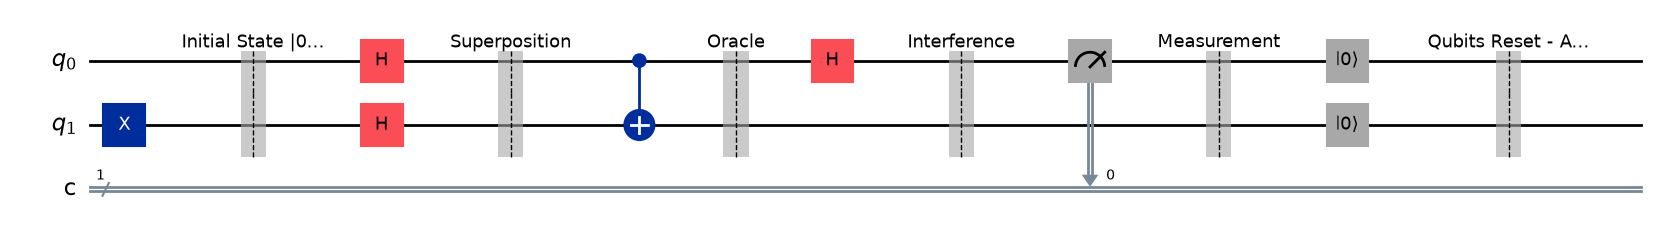

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# Choose the function f(x)
print("1: f(x) = 0      (constant)")
print("2: f(x) = 1      (constant)")
print("3: f(x) = x      (balanced)")
print("4: f(x) = NOT x  (balanced)")
choice = input("Choose function f(x) (1, 2, 3, 4): ")

if choice not in ["1", "2", "3", "4"]:
    raise ValueError("Enter 1, 2, 3 or 4.")

# Registers: q[0] = input x, q[1] = output y
q = QuantumRegister(2, 'q')
c = ClassicalRegister(1, 'c')

qc = QuantumCircuit(q, c)

# Prepare |0>|1>
qc.x(q[1])
qc.barrier(label="Initial State |0>|1>")

# Superposition
qc.h(q[0])
qc.h(q[1])
qc.barrier(label="Superposition")

# Oracle: |x>|y> -> |x>|y XOR f(x)>
if choice == "2":
    qc.x(q[1])
elif choice == "3":
    qc.cx(q[0], q[1])
elif choice == "4":
    qc.cx(q[0], q[1])
    qc.x(q[1])
qc.barrier(label="Oracle")

# Interference
qc.h(q[0])
qc.barrier(label="Interference")

# Measurement
qc.measure(q[0], c[0])
qc.barrier(label="Measurement")

# Reset both qubits after measurement
qc.reset(q[0])
qc.reset(q[1])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()
print("\nCounts:", counts)

measured = max(counts, key=counts.get)
answer = "CONSTANT" if measured == "0" else "BALANCED"
expected = "CONSTANT" if choice in ["1", "2"] else "BALANCED"

print("Measured q[0]:", measured)
print("Function is:", answer)
print("Correct:", answer == expected)

# Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("4_1_Deutsch.png", dpi=300, bbox_inches="tight")